# Predictions Test Analysis

Analysis of model predictions on the NIST23 test set (9-fold cross-validation), joining:
- `data/predicted/nps_inchikey_nist23_nist23_cv{0..8}.zip` — model outputs and cosine similarity scores (one zip per CV fold)
- `data/proc/nist23/spec_df.pkl` — spectrum metadata
- `data/proc/nist23/mol_df.pkl` — molecule metadata
- `data/classyfire/nist23_mol_classyfire.pkl` — ClassyFire chemical taxonomy labels

All 9 CV folds are concatenated into a single DataFrame before analysis.

In [ ]:
import gc
import pickle
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

DATA_ROOT = Path("../data")

## 1. Load Data

In [ ]:
# Load and combine predictions from all 9 CV folds
cv_dfs = []
for cv_idx in range(9):
    zip_path = DATA_ROOT / f"predicted/nps_inchikey_nist23_nist23_cv{cv_idx}.zip"
    with zipfile.ZipFile(zip_path) as zf:
        pkl_name = next(n for n in zf.namelist() if n.endswith("predictions_test.pkl"))
        with zf.open(pkl_name) as f:
            cv_df = pickle.load(f)
    cv_df["cv_fold"] = cv_idx
    cv_dfs.append(cv_df)
    print(f"  cv{cv_idx}: {len(cv_df):,} rows")

pred_df = pd.concat(cv_dfs, ignore_index=True)
print(f"\nCombined pred_df: {pred_df.shape}  ({pred_df['spec_id'].nunique():,} unique spec_ids)")

with open(DATA_ROOT / "proc/nist23/spec_df.pkl", "rb") as f:
    spec_df = pickle.load(f)

with open(DATA_ROOT / "proc/nist23/mol_df.pkl", "rb") as f:
    mol_df = pickle.load(f)
mol_df = mol_df.drop(columns=["mol"], errors="ignore")

with open(DATA_ROOT / "classyfire/nist23_mol_classyfire.pkl", "rb") as f:
    cf_df = pickle.load(f)

print(f"spec_df:  {spec_df.shape}")
print(f"mol_df:   {mol_df.shape}")
print(f"cf_df:    {cf_df.shape}")
del cv_dfs
gc.collect()


  cv0: 85,660 rows
  cv1: 83,574 rows
  cv2: 85,237 rows
  cv3: 85,873 rows
  cv4: 84,535 rows
  cv5: 84,931 rows
  cv6: 85,025 rows
  cv7: 85,048 rows
  cv8: 84,754 rows

Combined pred_df: (764637, 11)  (527,138 unique spec_ids)
spec_df:  (1899597, 22)
mol_df:   (52787, 13)
cf_df:    (52787, 10)


In [ ]:
pred_df.head(3)

,spec_id,mol_id,pred_mzs,pred_ints,pred_oos_prob,frag_formula_peak_idxs,frag_formula_peak_mzs,index_rebased,cos_sim_0.01,cos_hun,cv_fold
0,418,34523,"[220.0635986328125, 186.10256958007812, 222.07...","[1.2268697023391724, 4.8837103843688965, 999.9...",0.020965,"[30, 36, 38, 58, 407, 411]","[220.0635986328125, 186.10256958007812, 222.07...",True,0.999276,0.999276,0
1,419,34523,"[194.06053161621094, 173.09475708007812, 220.0...","[1.18855881690979, 4.235246658325195, 2.647926...",0.027789,"[1, 4, 30, 32, 36, 38, 40, 58, 147, 315, 407, ...","[194.06053161621094, 173.09475708007812, 220.0...",True,0.986549,0.986549,0
2,420,34523,"[194.06053161621094, 173.09475708007812, 174.1...","[1.0735852718353271, 13.810319900512695, 2.423...",0.031115,"[1, 4, 8, 28, 30, 32, 36, 38, 40, 58, 147, 315...","[194.06053161621094, 173.09475708007812, 174.1...",True,0.877749,0.877749,0


In [ ]:
spec_df.head(3)

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,nce,prec_mz,peaks,ri,group_id,ace_extra_1,nce_extra_1,ace_extra_2,nce_extra_2,ce_type
0,0,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461655,N2,...,44.0,132.0768,"[(53.0135, 2.4), (55.018, 55.2), (55.0292, 4.2...",NaN,0,NaN,NaN,NaN,NaN,single
1,1,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461656,N2,...,54.0,132.0768,"[(53.0135, 5.6), (55.018, 82.6), (55.0293, 7.1...",NaN,0,NaN,NaN,NaN,NaN,single
2,2,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461657,N2,...,65.0,132.0768,"[(51.0231, 8.7), (53.0136, 12.1), (55.018, 107...",NaN,0,NaN,NaN,NaN,NaN,single


In [ ]:
mol_df.head(3)

,smiles,mol_id,inchikey_s,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,*C1(C)C(OC2OC(CO)C(O)C(OC3OC(CO)C(O)C(O)C3O)C2...,0,,O=C(OC1CCCCO1)C12CCCCC1C1=CCC3C4CCC(OC5CC(OC6C...,C47H75*O19,,944.098,943.490255,67,74,0,True,0
1,BrC(Br)(Br)c1cnc2ccccc2n1,1,VCCOPRMZNNMFLI,c1ccc2nccnc2c1,C9H5Br3N2,"InChI=1S/C9H5Br3N2/c10-9(11,12)8-5-13-6-3-1-2-...",380.865,377.800284,14,15,0,True,0
2,BrC1=CCCN(Cc2ccccc2)C1,2,OFHMQSKRHZDSQE,C1=CCN(Cc2ccccc2)CC1,C12H14BrN,InChI=1S/C12H14BrN/c13-12-7-4-8-14(10-12)9-11-...,252.155,251.030962,14,15,0,True,0


## 2. Merge DataFrames

In [ ]:
# Merge predictions with spectrum metadata
spec_meta_cols = [
    "spec_id", "mol_id", "prec_type", "inst_type", "frag_mode",
    "ion_mode", "dset", "ace", "nce", "ce_type",
]
df = pred_df.merge(spec_df[spec_meta_cols], on=["spec_id", "mol_id"], how="left")

# Merge with molecule metadata
mol_meta_cols = ["mol_id", "smiles", "formula", "mw", "exact_mw", "num_atoms", "num_bonds", "inchikey_s"]
df = df.merge(mol_df[mol_meta_cols], on="mol_id", how="left")

# Merge with ClassyFire labels
cf_meta_cols = ["mol_id", "superklass", "klass", "subklass", "direct_parent"]
df = df.merge(cf_df[cf_meta_cols], on="mol_id", how="left")

# Remove MoNA spectra (adduct-matching artifact skews wrecall to ~0)
df = df[df["dset"] != "mona23"].copy()

print(f"Merged df (NIST23 only): {df.shape}")
df.head(3)
del pred_df, spec_df, mol_df, cf_df
gc.collect()


## 3. Overall Similarity Score Distribution

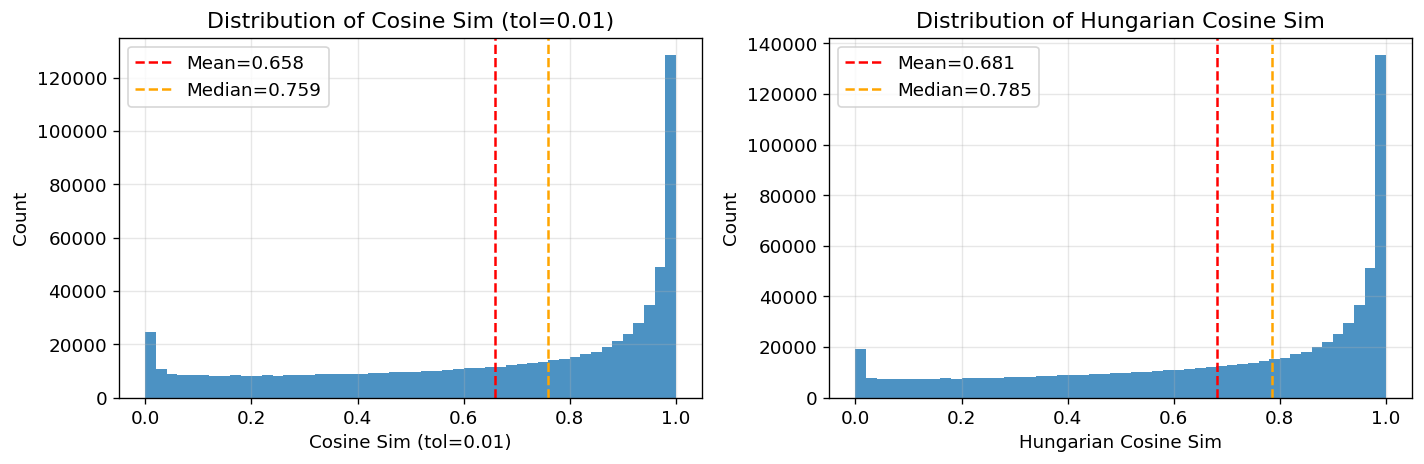

       cos_sim_0.01      cos_hun
count   764637.0000  764637.0000
mean         0.6584       0.6811
std          0.3201       0.3084
min          0.0000       0.0000
25%          0.4045       0.4520
50%          0.7589       0.7855
75%          0.9526       0.9579
max          1.0000       1.0000


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col, label in zip(
    axes,
    ["cos_sim_0.01", "cos_hun"],
    ["Cosine Sim (tol=0.01)", "Hungarian Cosine Sim"],
):
    ax.hist(df[col], bins=50, edgecolor="none", alpha=0.8)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label=f"Mean={df[col].mean():.3f}")
    ax.axvline(df[col].median(), color="orange", linestyle="--", label=f"Median={df[col].median():.3f}")
    ax.set_xlabel(label)
    ax.set_ylabel("Count")
    ax.set_title(f"Distribution of {label}")
    ax.legend()

plt.tight_layout()
plt.show()

print(df[["cos_sim_0.01", "cos_hun"]].describe().round(4))

## 4. Performance by Instrument Type

In [ ]:
inst_stats = (
    df.groupby("inst_type")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
inst_stats

cos_sim_0.01                 cos_hun                
                  mean  median   count    mean  median   count
inst_type                                                     
FT              0.6649  0.7649  721150  0.6906  0.7930  721150
IT              0.0293  0.0000     288  0.0123  0.0000     288
QTOF            0.5547  0.6238   43199  0.5264  0.5857   43199

/tmp/ipykernel_925805/3351175935.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=inst_order, patch_artist=True, showfliers=False,


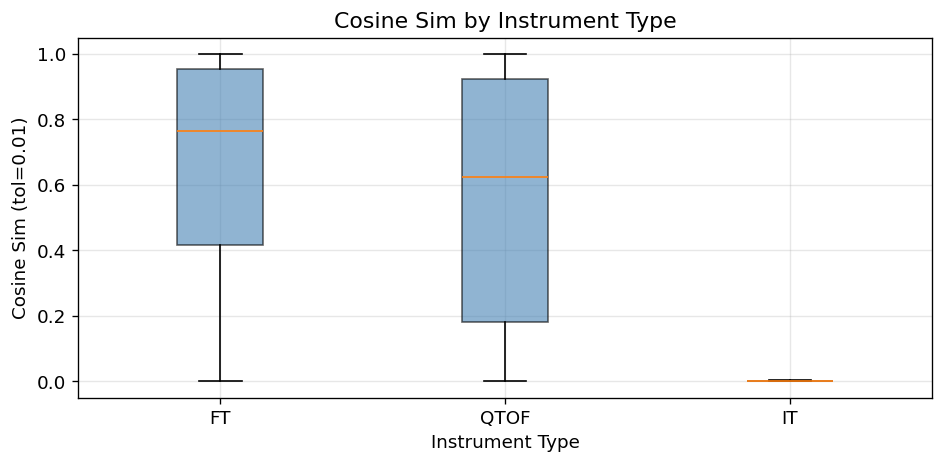

In [ ]:
inst_order = df.groupby("inst_type")["cos_sim_0.01"].median().sort_values(ascending=False).index.tolist()
groups = [df.loc[df["inst_type"] == g, "cos_sim_0.01"].dropna().values for g in inst_order]

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(groups, labels=inst_order, patch_artist=True, showfliers=False,
           boxprops=dict(facecolor="steelblue", alpha=0.6))
ax.set_title("Cosine Sim by Instrument Type")
ax.set_xlabel("Instrument Type")
ax.set_ylabel("Cosine Sim (tol=0.01)")
plt.tight_layout()
plt.show()

## 5. Performance by Precursor Type

In [ ]:
top_prec_types = df["prec_type"].value_counts().head(8).index
df_top = df[df["prec_type"].isin(top_prec_types)]

prec_stats = (
    df_top.groupby("prec_type")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
prec_stats

cos_sim_0.01                 cos_hun                
                  mean  median   count    mean  median   count
prec_type                                                     
[M+Cl]-         0.5701  0.6259    9092  0.6130  0.6978    9092
[M+H]+          0.6734  0.7678  514124  0.6925  0.7905  514124
[M+Na]+         0.6104  0.7204   57971  0.6403  0.7635   57971
[M-H]-          0.6359  0.7439  183441  0.6653  0.7798  183441
[M]+            0.1643  0.0833       9  0.1642  0.0833       9

/tmp/ipykernel_925805/2271524107.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=prec_order, patch_artist=True, showfliers=False,


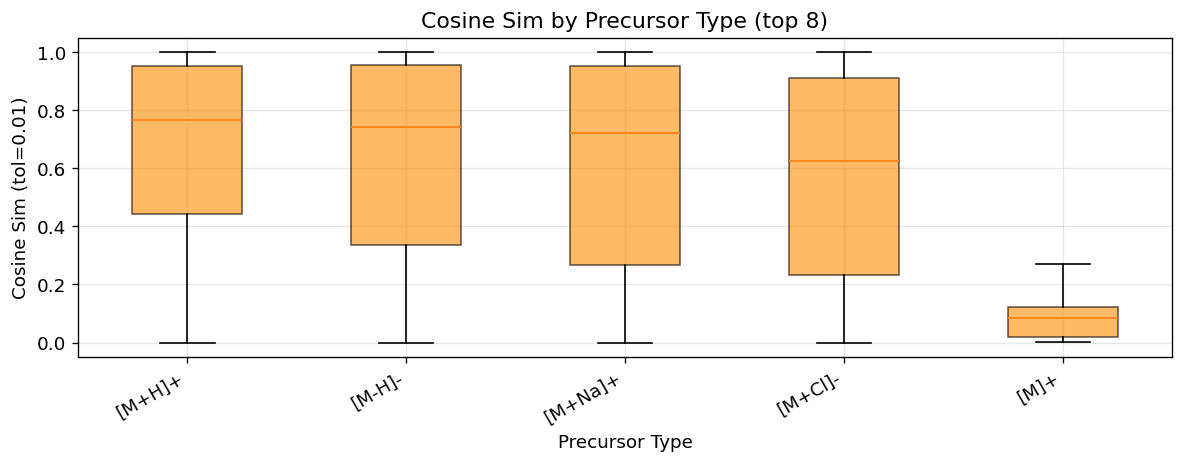

In [ ]:
prec_order = df_top.groupby("prec_type")["cos_sim_0.01"].median().sort_values(ascending=False).index.tolist()
groups = [df_top.loc[df_top["prec_type"] == g, "cos_sim_0.01"].dropna().values for g in prec_order]

fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(groups, labels=prec_order, patch_artist=True, showfliers=False,
           boxprops=dict(facecolor="darkorange", alpha=0.6))
ax.set_title("Cosine Sim by Precursor Type (top 8)")
ax.set_xlabel("Precursor Type")
ax.set_ylabel("Cosine Sim (tol=0.01)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 6. Performance by Ion Mode

In [ ]:
ion_stats = (
    df[df["ion_mode"].isin(["P", "N"])]
    .groupby("ion_mode")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
ion_stats

cos_sim_0.01                 cos_hun                
                 mean  median   count    mean  median   count
ion_mode                                                     
N              0.6328  0.7391  192525  0.6628  0.7759  192525
P              0.6670  0.7641  572107  0.6872  0.7882  572107

## 7. Performance by Fragmentation Mode (HCD vs CID)

In [ ]:
frag_stats = (
    df.groupby("frag_mode")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
frag_stats

cos_sim_0.01                 cos_hun                
                  mean  median   count    mean  median   count
frag_mode                                                     
CID             0.5275  0.5466  101494  0.5283  0.5532  101494
HCD             0.6784  0.7811  663143  0.7044  0.8079  663143

## 8. Effect of Collision Energy on Performance

Native CE type per instrument: **NCE (%)** for FT and IT, **ACE (eV)** for QTOF.

In [ ]:
# Per-instrument CE analysis using native CE type: QTOF → ACE (eV), FT/IT → NCE (%)
CE_CONFIG = {
    "FT":   {
        "col": "nce",
        "edges": [0, 20, 30, 40, 60, 80, 120, 200],
        "labels": ["0-20", "20-30", "30-40", "40-60", "60-80", "80-120", "120-200"],
        "label": "NCE (%)",
    },
    "QTOF": {
        "col": "ace",
        "edges": [0, 10, 20, 30, 50, 100, 200],
        "labels": ["0-10", "10-20", "20-30", "30-50", "50-100", "100-200"],
        "label": "ACE (eV)",
    },
    "IT": {
        "col": "nce",
        "edges": [0, 20, 30, 40, 60, 80, 120, 200],
        "labels": ["0-20", "20-30", "30-40", "40-60", "60-80", "80-120", "120-200"],
        "label": "NCE (%)",
    },
}

ce_stats = {}
for inst, cfg in CE_CONFIG.items():
    sub = df[df["inst_type"] == inst].copy()
    sub = sub[
        sub[cfg["col"]].notna()
        & (sub[cfg["col"]] > 0)
        & (sub[cfg["col"]] <= cfg["edges"][-1])
    ]
    if len(sub) == 0:
        print(f"\n=== {inst} ({cfg['label']}) — no valid CE data ===")
        continue
    sub["ce_bin"] = pd.cut(sub[cfg["col"]], bins=cfg["edges"], labels=cfg["labels"], right=True)
    stats = (
        sub.groupby("ce_bin", observed=True)[["cos_sim_0.01", "cos_hun"]]
        .agg(["mean", "median", "std", "count"])
        .round(4)
    )
    ce_stats[inst] = (stats, cfg["label"])
    print(f"\n=== {inst} ({cfg['label']}) ===")
    print(stats)

In [ ]:
colors = {"FT": "steelblue", "QTOF": "darkorange", "IT": "mediumseagreen"}
n_panels = len(ce_stats)
fig, axes = plt.subplots(1, n_panels, figsize=(5 * n_panels, 4))
if n_panels == 1:
    axes = [axes]

for ax, (inst, (stats, ce_label)) in zip(axes, ce_stats.items()):
    med = stats["cos_sim_0.01"]["median"]
    std = stats["cos_sim_0.01"]["std"]
    x = np.arange(len(med))
    ax.bar(x, med.values, color=colors.get(inst, "steelblue"), edgecolor="none",
           yerr=std.values, capsize=3, error_kw=dict(ecolor="black", elinewidth=1))
    ax.set_xticks(x)
    ax.set_xticklabels(med.index, rotation=30, ha="right")
    ax.set_title(f"{inst} — Median Cosine Sim ± Std by {ce_label}")
    ax.set_xlabel(ce_label)
    ax.set_ylabel("Median Cosine Sim (tol=0.01)")
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()


## 9. Performance by Dataset Source

In [ ]:
dset_stats = (
    df.groupby("dset")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
dset_stats

cos_sim_0.01                 cos_hun                
                   mean  median   count    mean  median   count
dset                                                           
mona23           0.5312  0.5628   65961  0.5455  0.5969   65961
nist23_hr1       0.6745  0.7782  396028  0.6954  0.8012  396028
nist23_hr2       0.6650  0.7626  302648  0.6919  0.7915  302648

## 10. Performance vs Molecular Properties

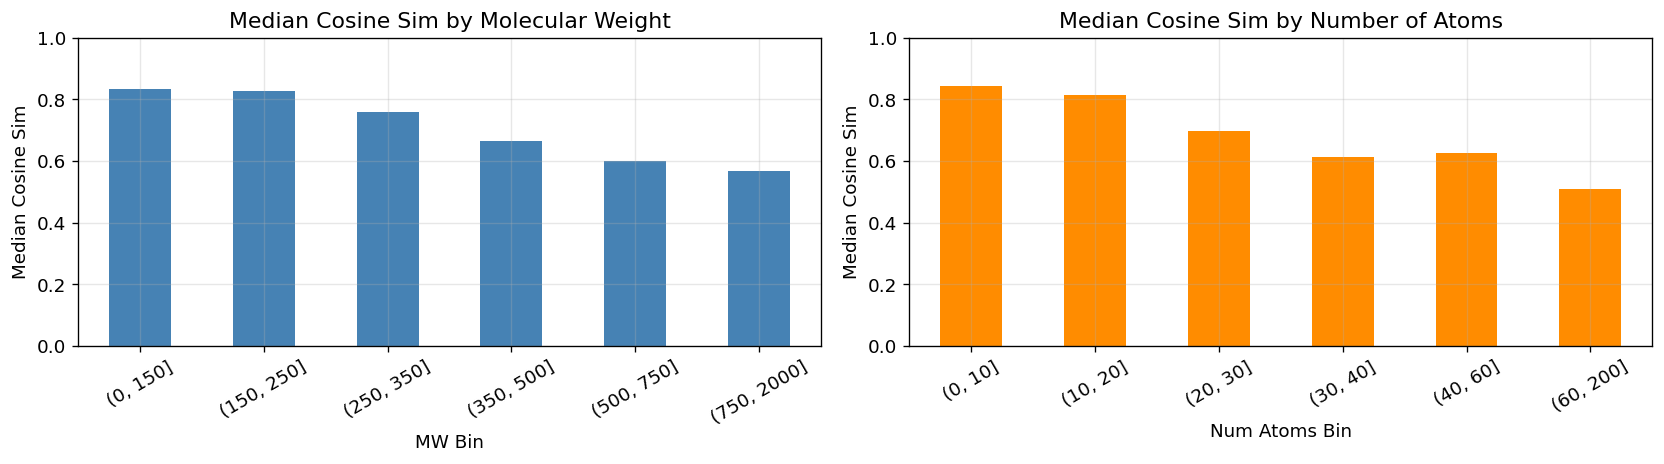

In [ ]:
df_mol = df[(df["mw"].notna()) & (df["num_atoms"].notna())].copy()
df_mol["mw_bin"] = pd.cut(df_mol["mw"], bins=[0, 150, 250, 350, 500, 750, 2000], right=True)
df_mol["natoms_bin"] = pd.cut(df_mol["num_atoms"], bins=[0, 10, 20, 30, 40, 60, 200], right=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

mw_med = df_mol.groupby("mw_bin", observed=True)["cos_sim_0.01"].median()
mw_med.plot(kind="bar", ax=axes[0], color="steelblue", edgecolor="none")
axes[0].set_title("Median Cosine Sim by Molecular Weight")
axes[0].set_xlabel("MW Bin")
axes[0].set_ylabel("Median Cosine Sim")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=30)

na_med = df_mol.groupby("natoms_bin", observed=True)["cos_sim_0.01"].median()
na_med.plot(kind="bar", ax=axes[1], color="darkorange", edgecolor="none")
axes[1].set_title("Median Cosine Sim by Number of Atoms")
axes[1].set_xlabel("Num Atoms Bin")
axes[1].set_ylabel("Median Cosine Sim")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 11. Out-of-Spectrum Probability vs Similarity

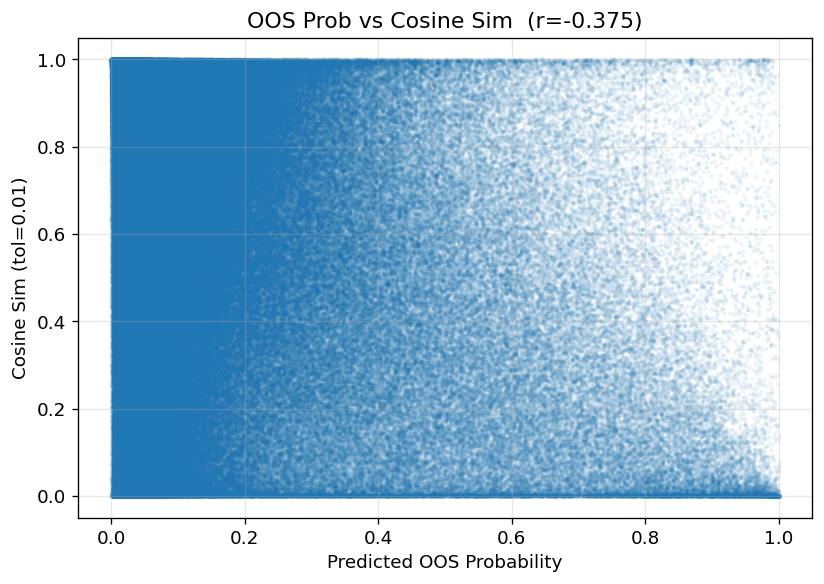

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    df["pred_oos_prob"],
    df["cos_sim_0.01"],
    alpha=0.05,
    s=3,
    rasterized=True,
)
corr = df[["pred_oos_prob", "cos_sim_0.01"]].corr().iloc[0, 1]
ax.set_xlabel("Predicted OOS Probability")
ax.set_ylabel("Cosine Sim (tol=0.01)")
ax.set_title(f"OOS Prob vs Cosine Sim  (r={corr:.3f})")
plt.tight_layout()
plt.show()

In [ ]:
df["oos_bin"] = pd.cut(df["pred_oos_prob"], bins=[0, 0.05, 0.1, 0.2, 0.5, 1.0], right=True)
oos_stats = (
    df.groupby("oos_bin", observed=True)[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
oos_stats

cos_sim_0.01                 cos_hun                
                    mean  median   count    mean  median   count
oos_bin                                                         
(0.0, 0.05]       0.7602  0.8985  323533  0.7908  0.9137  323533
(0.05, 0.1]       0.6807  0.7877  134732  0.7097  0.8149  134732
(0.1, 0.2]        0.6292  0.6991  120704  0.6525  0.7250  120704
(0.2, 0.5]        0.5417  0.5613  129367  0.5514  0.5764  129367
(0.5, 1.0]        0.3508  0.2788   56301  0.3409  0.2716   56301

## 12. Top / Bottom Predictions

In [ ]:
display_cols = ["spec_id", "mol_id", "smiles", "formula", "prec_type", "inst_type", "cos_sim_0.01", "cos_hun"]

print("=== Top 10 predictions ===")
display(df.nlargest(10, "cos_sim_0.01")[display_cols].reset_index(drop=True))

print("=== Bottom 10 predictions ===")
display(df.nsmallest(10, "cos_sim_0.01")[display_cols].reset_index(drop=True))

=== Top 10 predictions ===


,spec_id,mol_id,smiles,formula,prec_type,inst_type,cos_sim_0.01,cos_hun
0,1829378,15901,CCCCCCCCCCCCCCCC(=O)O,C16H32O2,[M-H]-,QTOF,1.0,1.0
1,1845046,12607,CCC(Cc1c(I)cc(I)c(N)c1I)C(=O)O,C11H12I3NO2,[M-H]-,FT,1.0,1.0
2,1873007,35635,Cn1sc(Cl)cc1=O,C4H4ClNOS,[M+H]+,FT,1.0,1.0
3,1899576,26760,COc1cc2c(c3oc(=O)c4c(c13)CCC4=O)C1C=COC1O2,C17H12O6,[M+Na]+,FT,1.0,1.0
4,1845045,12607,CCC(Cc1c(I)cc(I)c(N)c1I)C(=O)O,C11H12I3NO2,[M-H]-,FT,1.0,1.0
5,1801448,51067,OCCOCCOCCOCCOCCOCCO,C12H26O7,[M+Na]+,FT,1.0,1.0
6,1899576,26760,COc1cc2c(c3oc(=O)c4c(c13)CCC4=O)C1C=COC1O2,C17H12O6,[M+Na]+,FT,1.0,1.0
7,1801458,51069,OCCOCCOCCOCCOCCOCCOCCOCCOCCO,C18H38O10,[M+Na]+,FT,1.0,1.0
8,1893579,48819,O=S(=O)(O)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)F,C5HF11O3S,[M-H]-,QTOF,1.0,1.0
9,1870098,47742,O=C1NS(=O)(=O)c2ccccc21,C7H5NO3S,[M-H]-,FT,1.0,1.0


=== Bottom 10 predictions ===


,spec_id,mol_id,smiles,formula,prec_type,inst_type,cos_sim_0.01,cos_hun
0,9358,19838,CCOc1cc(=O)oc2ccc(OC)cc12,C12H12O4,[M+H]+,FT,0.0,0.764567
1,9564,13772,CCCC(O)CC,C6H14O,[M+H]+,QTOF,0.0,0.000000
2,9671,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.057358
3,9672,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.028581
4,9673,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.012589
5,9674,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.006699
6,9675,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.002818
7,9676,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.004042
8,9677,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.000000
9,9678,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.001769


## 13. Performance by ClassyFire Superclass

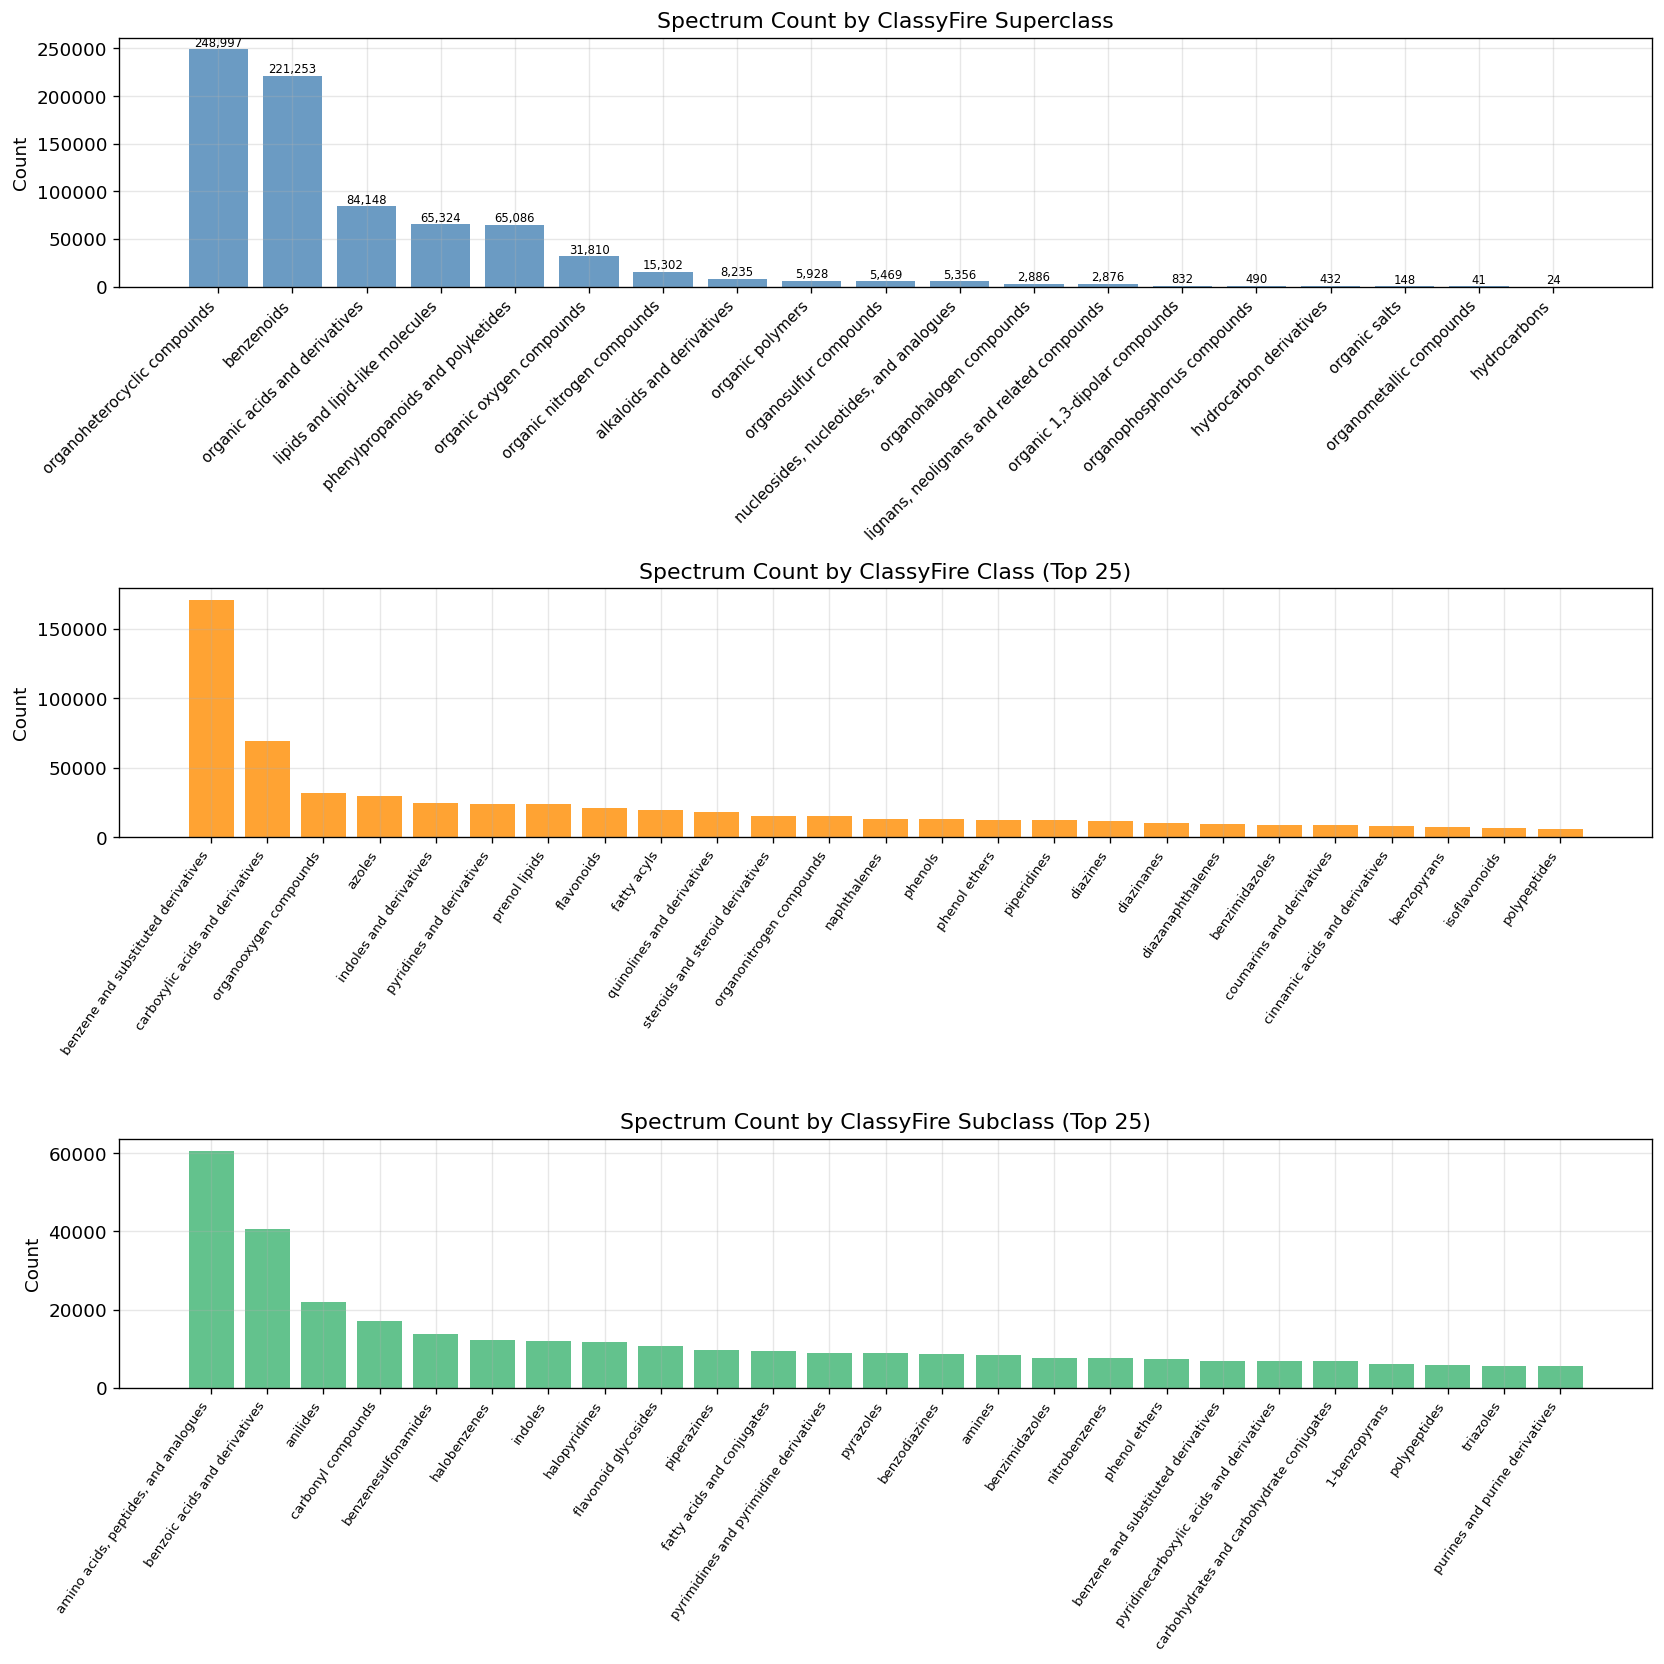

Spectra with no superklass label: 0
Spectra with no klass label:      2,115
Spectra with no subklass label:   0


In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 14))

# Superclass distribution (all)
super_counts = df["superklass"].value_counts()
axes[0].bar(range(len(super_counts)), super_counts.values, color="steelblue", alpha=0.8)
axes[0].set_xticks(range(len(super_counts)))
axes[0].set_xticklabels(super_counts.index, rotation=45, ha="right", fontsize=9)
axes[0].set_title("Spectrum Count by ClassyFire Superclass")
axes[0].set_ylabel("Count")
for i, v in enumerate(super_counts.values):
    axes[0].text(i, v + 20, f"{v:,}", ha="center", va="bottom", fontsize=7)

# Class distribution (top 25)
klass_counts = df["klass"].value_counts().head(25)
axes[1].bar(range(len(klass_counts)), klass_counts.values, color="darkorange", alpha=0.8)
axes[1].set_xticks(range(len(klass_counts)))
axes[1].set_xticklabels(klass_counts.index, rotation=55, ha="right", fontsize=8)
axes[1].set_title("Spectrum Count by ClassyFire Class (Top 25)")
axes[1].set_ylabel("Count")

# Subclass distribution (top 25)
sub_counts = df["subklass"].value_counts().head(25)
axes[2].bar(range(len(sub_counts)), sub_counts.values, color="mediumseagreen", alpha=0.8)
axes[2].set_xticks(range(len(sub_counts)))
axes[2].set_xticklabels(sub_counts.index, rotation=55, ha="right", fontsize=8)
axes[2].set_title("Spectrum Count by ClassyFire Subclass (Top 25)")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

print(f"Spectra with no superklass label: {df['superklass'].isna().sum():,}")
print(f"Spectra with no klass label:      {df['klass'].isna().sum():,}")
print(f"Spectra with no subklass label:   {df['subklass'].isna().sum():,}")

In [ ]:
cf_super_stats = (
    df.dropna(subset=["superklass"])
    .groupby("superklass")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
cf_super_stats.sort_values(("cos_sim_0.01", "median"), ascending=False)

cos_sim_0.01                  \
                                                  mean  median   count   
superklass                                                               
nucleosides, nucleotides, and analogues         0.7337  0.9012    5356   
organic nitrogen compounds                      0.6913  0.7981   15302   
benzenoids                                      0.6842  0.7966  221253   
organic acids and derivatives                   0.6627  0.7772   84148   
organohalogen compounds                         0.6269  0.7689    2886   
organosulfur compounds                          0.6484  0.7606    5469   
organoheterocyclic compounds                    0.6615  0.7574  248997   
organic oxygen compounds                        0.6417  0.7318   31810   
phenylpropanoids and polyketides                0.6328  0.7152   65086   
organophosphorus compounds                      0.6262  0.7147     490   
organic polymers                                0.6177  0.7049    5928   
alkaloids and derivatives                       0.6051  0.6872    8235   
lipids and lipid-like molecules                 0.5980  0.6660   65324   
organic 1,3-dipolar compounds                   0.5923  0.6470     832   
hydrocarbons                                    0.3997  0.4858      24   
lignans, neolignans and related compounds       0.4688  0.4399    2876   
hydrocarbon derivatives                         0.3912  0.3347     432   
organic salts                                   0.3910  0.2680     148   
organometallic compounds                        0.3366  0.1316      41   

                                          cos_hun                  
                                             mean  median   count  
superklass                                                         
nucleosides, nucleotides, and analogues    0.7239  0.8912    5356  
organic nitrogen compounds                 0.7113  0.8227   15302  
benzenoids                                 0.7079  0.8199  221253  
organic acids and derivatives              0.6753  0.7939   84148  
organohalogen compounds                    0.6540  0.7954    2886  
organosulfur compounds                     0.6911  0.8093    5469  
organoheterocyclic compounds               0.6827  0.7827  248997  
organic oxygen compounds                   0.6704  0.7654   31810  
phenylpropanoids and polyketides           0.6666  0.7585   65086  
organophosphorus compounds                 0.6573  0.7694     490  
organic polymers                           0.6077  0.7030    5928  
alkaloids and derivatives                  0.6107  0.7004    8235  
lipids and lipid-like molecules            0.6266  0.7067   65324  
organic 1,3-dipolar compounds              0.6196  0.6743     832  
hydrocarbons                               0.4003  0.4858      24  
lignans, neolignans and related compounds  0.5380  0.5792    2876  
hydrocarbon derivatives                    0.3757  0.3234     432  
organic salts                              0.3947  0.2798     148  
organometallic compounds                   0.3366  0.1316      41

/tmp/ipykernel_925805/100713300.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=[f"{s}\n(n={c:,})" for s, c in zip(super_order, counts)],


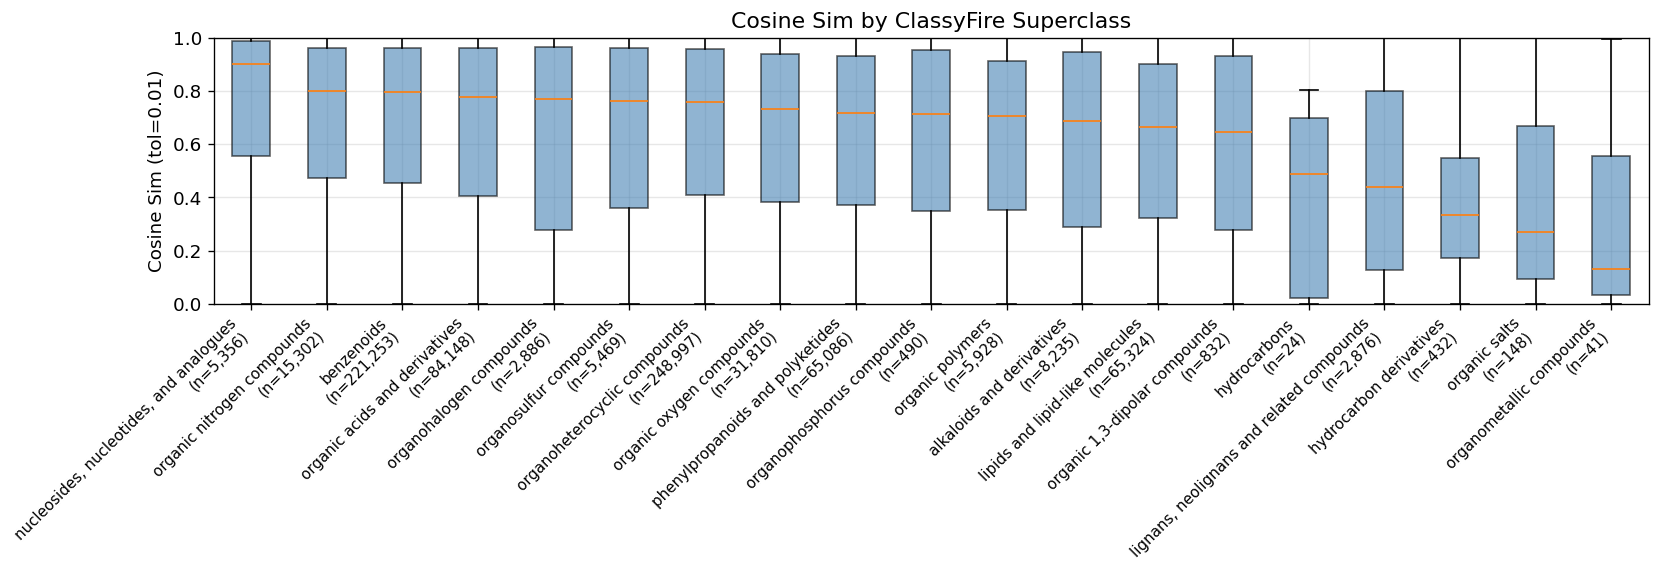

In [ ]:
df_cf = df.dropna(subset=["superklass"])
super_order = df_cf.groupby("superklass")["cos_sim_0.01"].median().sort_values(ascending=False).index.tolist()
groups = [df_cf.loc[df_cf["superklass"] == g, "cos_sim_0.01"].values for g in super_order]
counts = [len(g) for g in groups]

fig, ax = plt.subplots(figsize=(14, 5))
ax.boxplot(groups, labels=[f"{s}\n(n={c:,})" for s, c in zip(super_order, counts)],
           patch_artist=True, showfliers=False,
           boxprops=dict(facecolor="steelblue", alpha=0.6))
ax.set_title("Cosine Sim by ClassyFire Superclass")
ax.set_ylabel("Cosine Sim (tol=0.01)")
ax.set_ylim(0, 1)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.tight_layout()
plt.show()

## 14. Performance by ClassyFire Class (Top 25)

In [ ]:
top25_classes = df["klass"].value_counts().head(25).index.tolist()
df_klass = df[df["klass"].isin(top25_classes)].dropna(subset=["klass"])

cf_klass_stats = (
    df_klass.groupby("klass")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
cf_klass_stats.sort_values(("cos_sim_0.01", "median"), ascending=False)

cos_sim_0.01                 cos_hun  \
                                            mean  median   count    mean   
klass                                                                      
piperidines                               0.7358  0.8660   12295  0.7541   
benzimidazoles                            0.7093  0.8282    8989  0.7337   
cinnamic acids and derivatives            0.6918  0.8159    7976  0.7227   
benzene and substituted derivatives       0.6965  0.8121  170765  0.7187   
indoles and derivatives                   0.6914  0.8104   24769  0.7182   
organonitrogen compounds                  0.6913  0.7981   15302  0.7113   
carboxylic acids and derivatives          0.6713  0.7905   69005  0.6835   
pyridines and derivatives                 0.6809  0.7839   24108  0.6965   
diazinanes                                0.6957  0.7819    9978  0.7155   
naphthalenes                              0.6694  0.7744   13227  0.7124   
fatty acyls                               0.6657  0.7729   19453  0.6866   
phenols                                   0.6554  0.7683   12939  0.6730   
phenol ethers                             0.6744  0.7675   12364  0.6977   
quinolines and derivatives                0.6694  0.7664   17937  0.6923   
azoles                                    0.6631  0.7536   29471  0.6831   
diazines                                  0.6571  0.7489   11838  0.6782   
flavonoids                                0.6499  0.7398   21315  0.6967   
diazanaphthalenes                         0.6551  0.7345    9121  0.6721   
organooxygen compounds                    0.6414  0.7314   31737  0.6702   
polypeptides                              0.6177  0.7049    5928  0.6077   
coumarins and derivatives                 0.6180  0.6846    8654  0.6376   
isoflavonoids                             0.5823  0.6075    6254  0.6058   
prenol lipids                             0.5650  0.6023   23531  0.5951   
steroids and steroid derivatives          0.5559  0.5861   15332  0.5848   
benzopyrans                               0.5305  0.5181    7434  0.5627   

                                                     
                                     median   count  
klass                                                
piperidines                          0.8793   12295  
benzimidazoles                       0.8479    8989  
cinnamic acids and derivatives       0.8412    7976  
benzene and substituted derivatives  0.8322  170765  
indoles and derivatives              0.8397   24769  
organonitrogen compounds             0.8227   15302  
carboxylic acids and derivatives     0.8060   69005  
pyridines and derivatives            0.8013   24108  
diazinanes                           0.8018    9978  
naphthalenes                         0.8176   13227  
fatty acyls                          0.7984   19453  
phenols                              0.7904   12939  
phenol ethers                        0.7899   12364  
quinolines and derivatives           0.7910   17937  
azoles                               0.7775   29471  
diazines                             0.7734   11838  
flavonoids                           0.7890   21315  
diazanaphthalenes                    0.7561    9121  
organooxygen compounds               0.7649   31737  
polypeptides                         0.7030    5928  
coumarins and derivatives            0.7089    8654  
isoflavonoids                        0.6424    6254  
prenol lipids                        0.6424   23531  
steroids and steroid derivatives     0.6269   15332  
benzopyrans                          0.5711    7434

/tmp/ipykernel_925805/3139794100.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=[f"{k}\n(n={c:,})" for k, c in zip(klass_order, counts)],


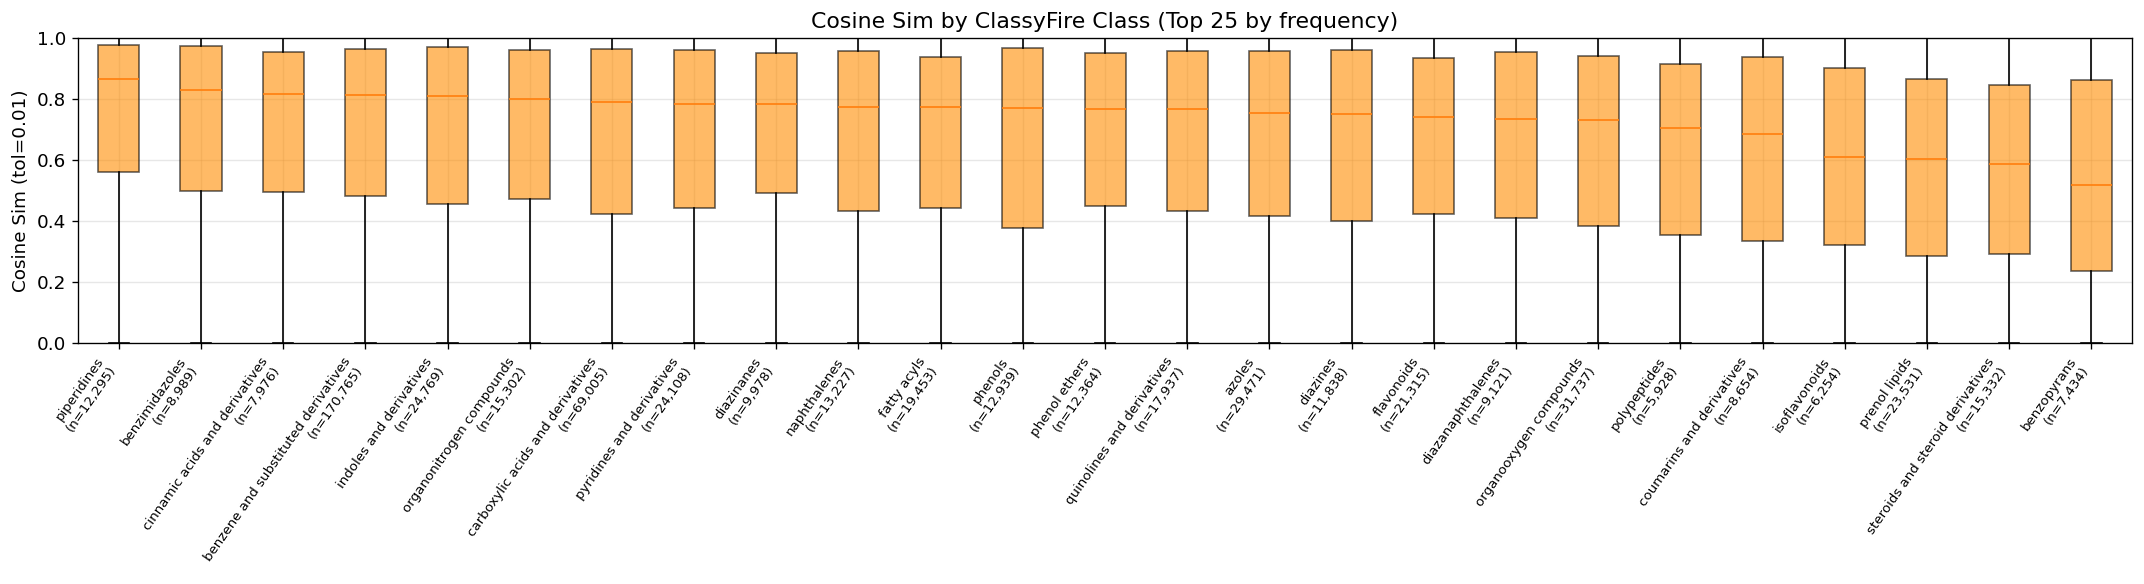

In [ ]:
klass_order = df_klass.groupby("klass")["cos_sim_0.01"].median().sort_values(ascending=False).index.tolist()
groups = [df_klass.loc[df_klass["klass"] == g, "cos_sim_0.01"].values for g in klass_order]
counts = [len(g) for g in groups]

fig, ax = plt.subplots(figsize=(18, 5))
ax.boxplot(groups, labels=[f"{k}\n(n={c:,})" for k, c in zip(klass_order, counts)],
           patch_artist=True, showfliers=False,
           boxprops=dict(facecolor="darkorange", alpha=0.6))
ax.set_title("Cosine Sim by ClassyFire Class (Top 25 by frequency)")
ax.set_ylabel("Cosine Sim (tol=0.01)")
ax.set_ylim(0, 1)
plt.xticks(rotation=55, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

## 15. Performance by ClassyFire Subclass (Top 25)

In [ ]:
top25_subklasses = df["subklass"].value_counts().head(25).index.tolist()
df_sub = df[df["subklass"].isin(top25_subklasses)].dropna(subset=["subklass"])

cf_sub_stats = (
    df_sub.groupby("subklass")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
cf_sub_stats.sort_values(("cos_sim_0.01", "median"), ascending=False)

cos_sim_0.01                cos_hun  \
                                                  mean  median  count    mean   
subklass                                                                        
halobenzenes                                    0.7523  0.8787  12107  0.7718   
anilides                                        0.7337  0.8465  22009  0.7552   
benzene and substituted derivatives             0.7118  0.8448   6834  0.7262   
benzimidazoles                                  0.7153  0.8369   7713  0.7401   
benzoic acids and derivatives                   0.7008  0.8236  40536  0.7266   
amines                                          0.7009  0.8104   8447  0.7253   
pyridinecarboxylic acids and derivatives        0.6903  0.8090   6747  0.7032   
purines and purine derivatives                  0.6969  0.8064   5530  0.7080   
amino acids, peptides, and analogues            0.6819  0.8048  60623  0.6945   
triazoles                                       0.6881  0.8039   5643  0.7185   
indoles                                         0.6850  0.8005  12048  0.7072   
fatty acids and conjugates                      0.6823  0.7987   9422  0.6894   
flavonoid glycosides                            0.6756  0.7845  10605  0.7448   
phenol ethers                                   0.6857  0.7814   7254  0.7119   
piperazines                                     0.6947  0.7807   9766  0.7147   
carbonyl compounds                              0.6798  0.7796  17072  0.7011   
halopyridines                                   0.6781  0.7773  11757  0.6938   
pyrimidines and pyrimidine derivatives          0.6671  0.7692   8986  0.6903   
benzodiazines                                   0.6539  0.7329   8601  0.6715   
benzenesulfonamides                             0.6364  0.7238  13828  0.6687   
pyrazoles                                       0.6452  0.7069   8908  0.6673   
polypeptides                                    0.6177  0.7049   5928  0.6077   
carbohydrates and carbohydrate conjugates       0.5911  0.6577   6718  0.6209   
nitrobenzenes                                   0.5973  0.6450   7481  0.6159   
1-benzopyrans                                   0.5371  0.5367   6171  0.5729   

                                                          
                                           median  count  
subklass                                                  
halobenzenes                               0.8901  12107  
anilides                                   0.8627  22009  
benzene and substituted derivatives        0.8565   6834  
benzimidazoles                             0.8562   7713  
benzoic acids and derivatives              0.8461  40536  
amines                                     0.8395   8447  
pyridinecarboxylic acids and derivatives   0.8282   6747  
purines and purine derivatives             0.8190   5530  
amino acids, peptides, and analogues       0.8201  60623  
triazoles                                  0.8351   5643  
indoles                                    0.8247  12048  
fatty acids and conjugates                 0.8124   9422  
flavonoid glycosides                       0.8440  10605  
phenol ethers                              0.8038   7254  
piperazines                                0.8010   9766  
carbonyl compounds                         0.7991  17072  
halopyridines                              0.7906  11757  
pyrimidines and pyrimidine derivatives     0.7970   8986  
benzodiazines                              0.7540   8601  
benzenesulfonamides                        0.7632  13828  
pyrazoles                                  0.7323   8908  
polypeptides                               0.7030   5928  
carbohydrates and carbohydrate conjugates  0.7048   6718  
nitrobenzenes                              0.6716   7481  
1-benzopyrans                              0.5892   6171

/tmp/ipykernel_925805/2366441236.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=[f"{s}\n(n={c:,})" for s, c in zip(sub_order, counts)],


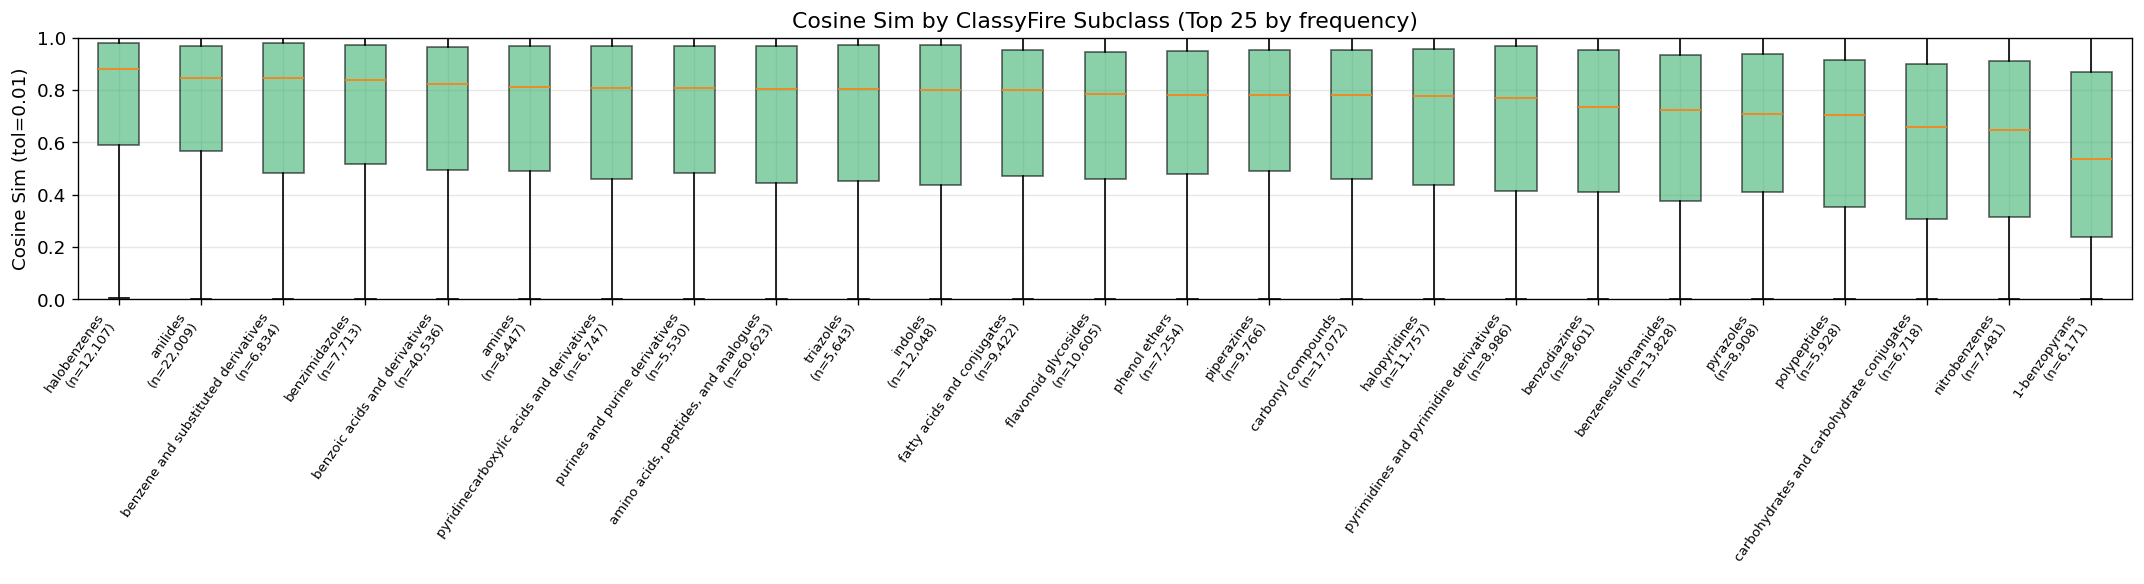

In [ ]:
sub_order = df_sub.groupby("subklass")["cos_sim_0.01"].median().sort_values(ascending=False).index.tolist()
groups = [df_sub.loc[df_sub["subklass"] == g, "cos_sim_0.01"].values for g in sub_order]
counts = [len(g) for g in groups]

fig, ax = plt.subplots(figsize=(18, 5))
ax.boxplot(groups, labels=[f"{s}\n(n={c:,})" for s, c in zip(sub_order, counts)],
           patch_artist=True, showfliers=False,
           boxprops=dict(facecolor="mediumseagreen", alpha=0.6))
ax.set_title("Cosine Sim by ClassyFire Subclass (Top 25 by frequency)")
ax.set_ylabel("Cosine Sim (tol=0.01)")
ax.set_ylim(0, 1)
plt.xticks(rotation=55, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

## 16. Performance Bias by ClassyFire Category

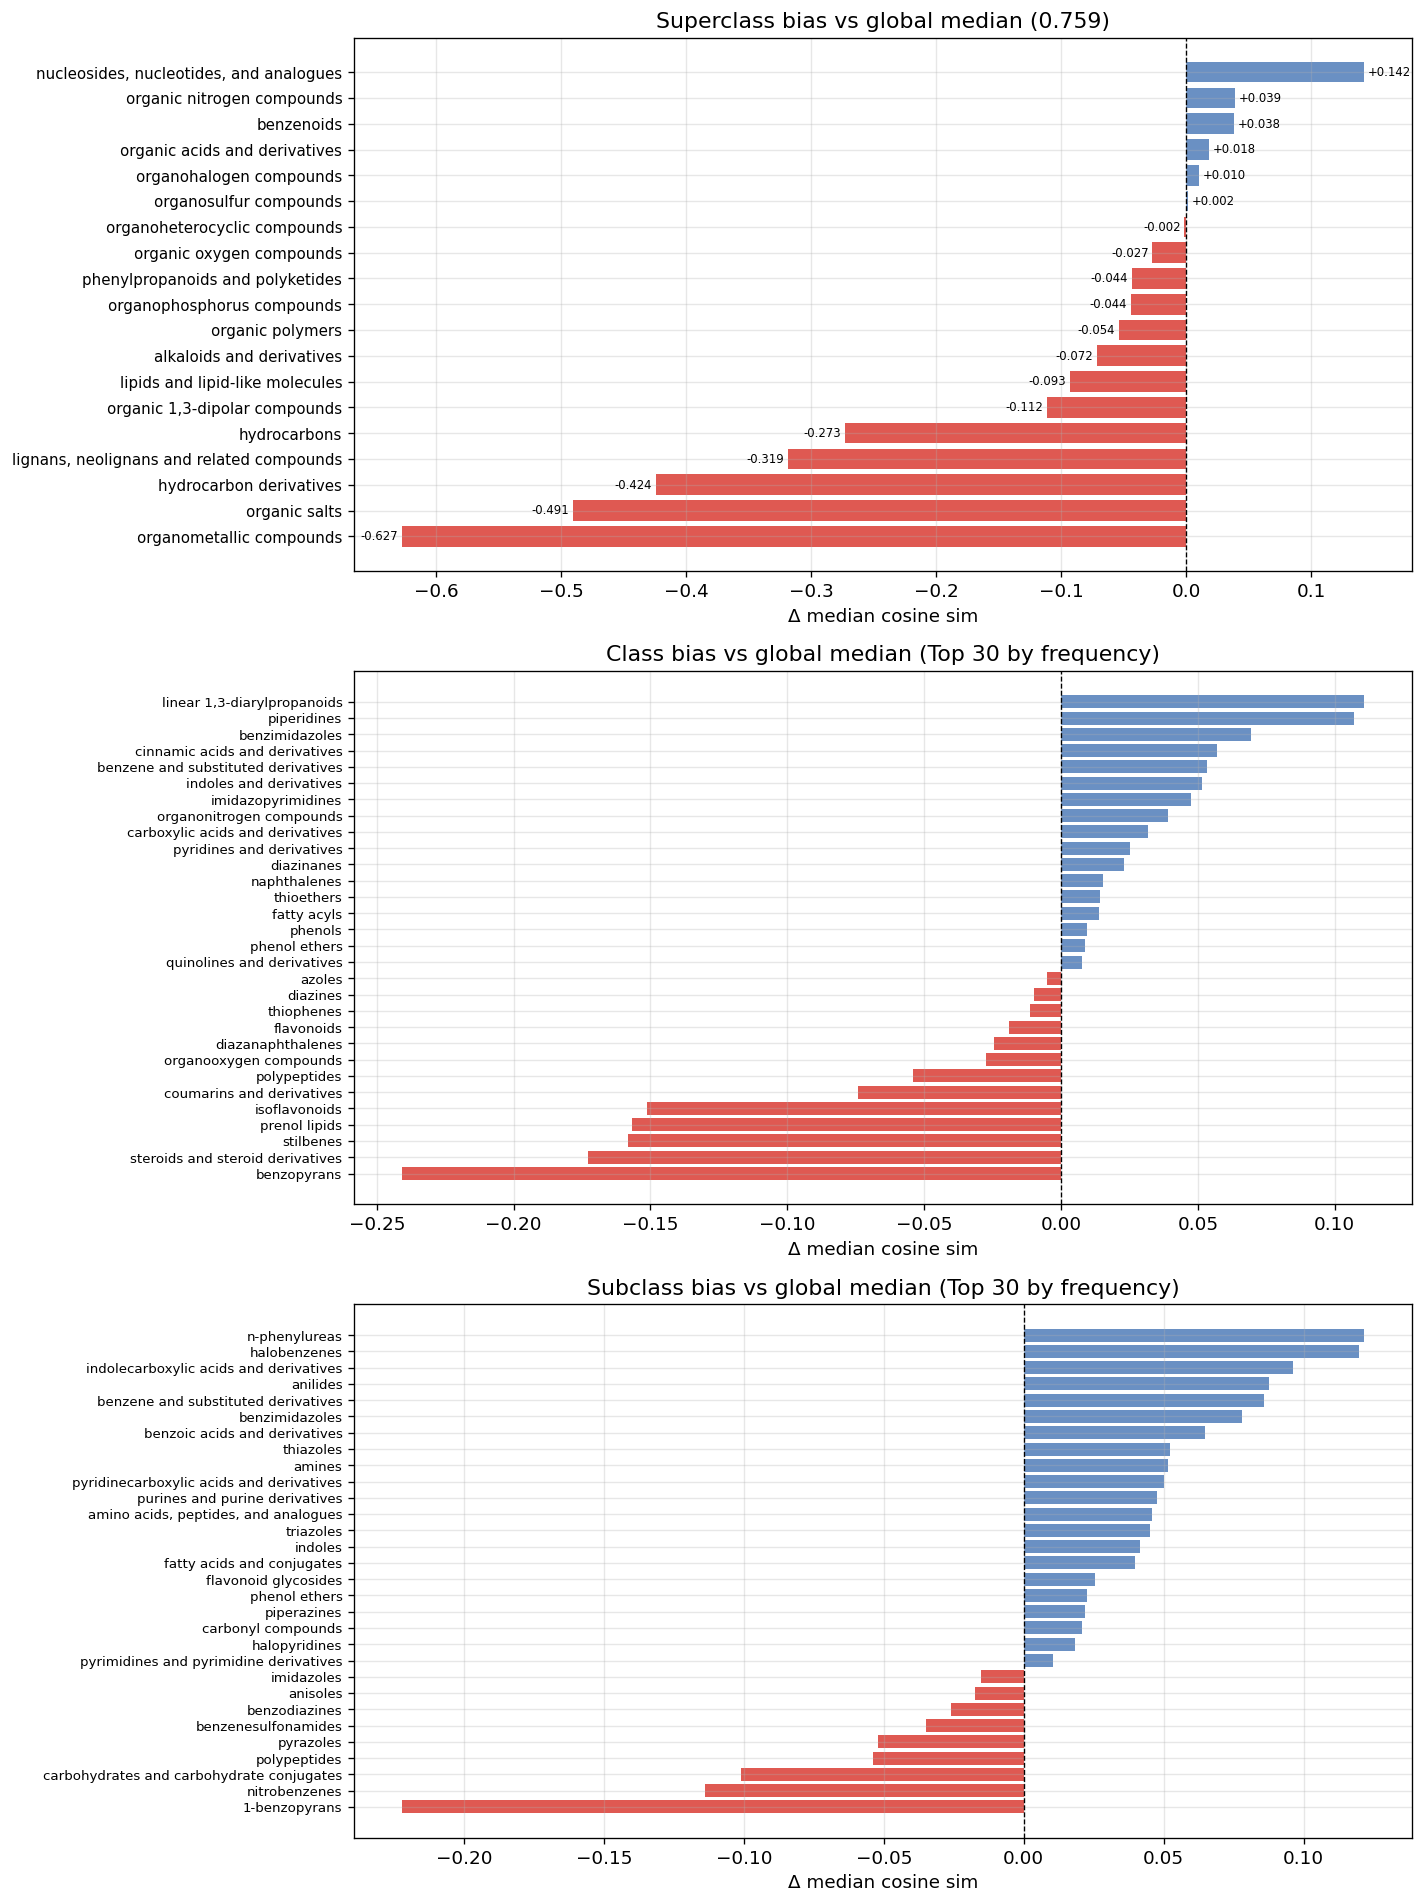

In [ ]:
global_median = df["cos_sim_0.01"].median()

fig, axes = plt.subplots(3, 1, figsize=(12, 16))

# --- Superclass bias ---
super_med = (
    df.dropna(subset=["superklass"])
    .groupby("superklass")["cos_sim_0.01"]
    .median()
    .sort_values()
)
super_bias = super_med - global_median
colors = ["#d73027" if v < 0 else "#4575b4" for v in super_bias]
axes[0].barh(range(len(super_bias)), super_bias.values, color=colors, alpha=0.8)
axes[0].set_yticks(range(len(super_bias)))
axes[0].set_yticklabels(super_bias.index, fontsize=9)
axes[0].axvline(0, color="black", linewidth=0.8, linestyle="--")
axes[0].set_title(f"Superclass bias vs global median ({global_median:.3f})")
axes[0].set_xlabel("Δ median cosine sim")
for i, v in enumerate(super_bias.values):
    axes[0].text(v + (0.003 if v >= 0 else -0.003), i, f"{v:+.3f}",
                 va="center", ha="left" if v >= 0 else "right", fontsize=7)

# --- Class bias (top 30 by count) ---
top30_classes = df["klass"].value_counts().head(30).index
klass_med = (
    df[df["klass"].isin(top30_classes)]
    .dropna(subset=["klass"])
    .groupby("klass")["cos_sim_0.01"]
    .median()
    .sort_values()
)
klass_bias = klass_med - global_median
colors = ["#d73027" if v < 0 else "#4575b4" for v in klass_bias]
axes[1].barh(range(len(klass_bias)), klass_bias.values, color=colors, alpha=0.8)
axes[1].set_yticks(range(len(klass_bias)))
axes[1].set_yticklabels(klass_bias.index, fontsize=8)
axes[1].axvline(0, color="black", linewidth=0.8, linestyle="--")
axes[1].set_title("Class bias vs global median (Top 30 by frequency)")
axes[1].set_xlabel("Δ median cosine sim")

# --- Subclass bias (top 30 by count) ---
top30_sub = df["subklass"].value_counts().head(30).index
sub_med = (
    df[df["subklass"].isin(top30_sub)]
    .dropna(subset=["subklass"])
    .groupby("subklass")["cos_sim_0.01"]
    .median()
    .sort_values()
)
sub_bias = sub_med - global_median
colors = ["#d73027" if v < 0 else "#4575b4" for v in sub_bias]
axes[2].barh(range(len(sub_bias)), sub_bias.values, color=colors, alpha=0.8)
axes[2].set_yticks(range(len(sub_bias)))
axes[2].set_yticklabels(sub_bias.index, fontsize=8)
axes[2].axvline(0, color="black", linewidth=0.8, linestyle="--")
axes[2].set_title("Subclass bias vs global median (Top 30 by frequency)")
axes[2].set_xlabel("Δ median cosine sim")

plt.tight_layout()
plt.show()

/tmp/ipykernel_925805/2156949452.py:75: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


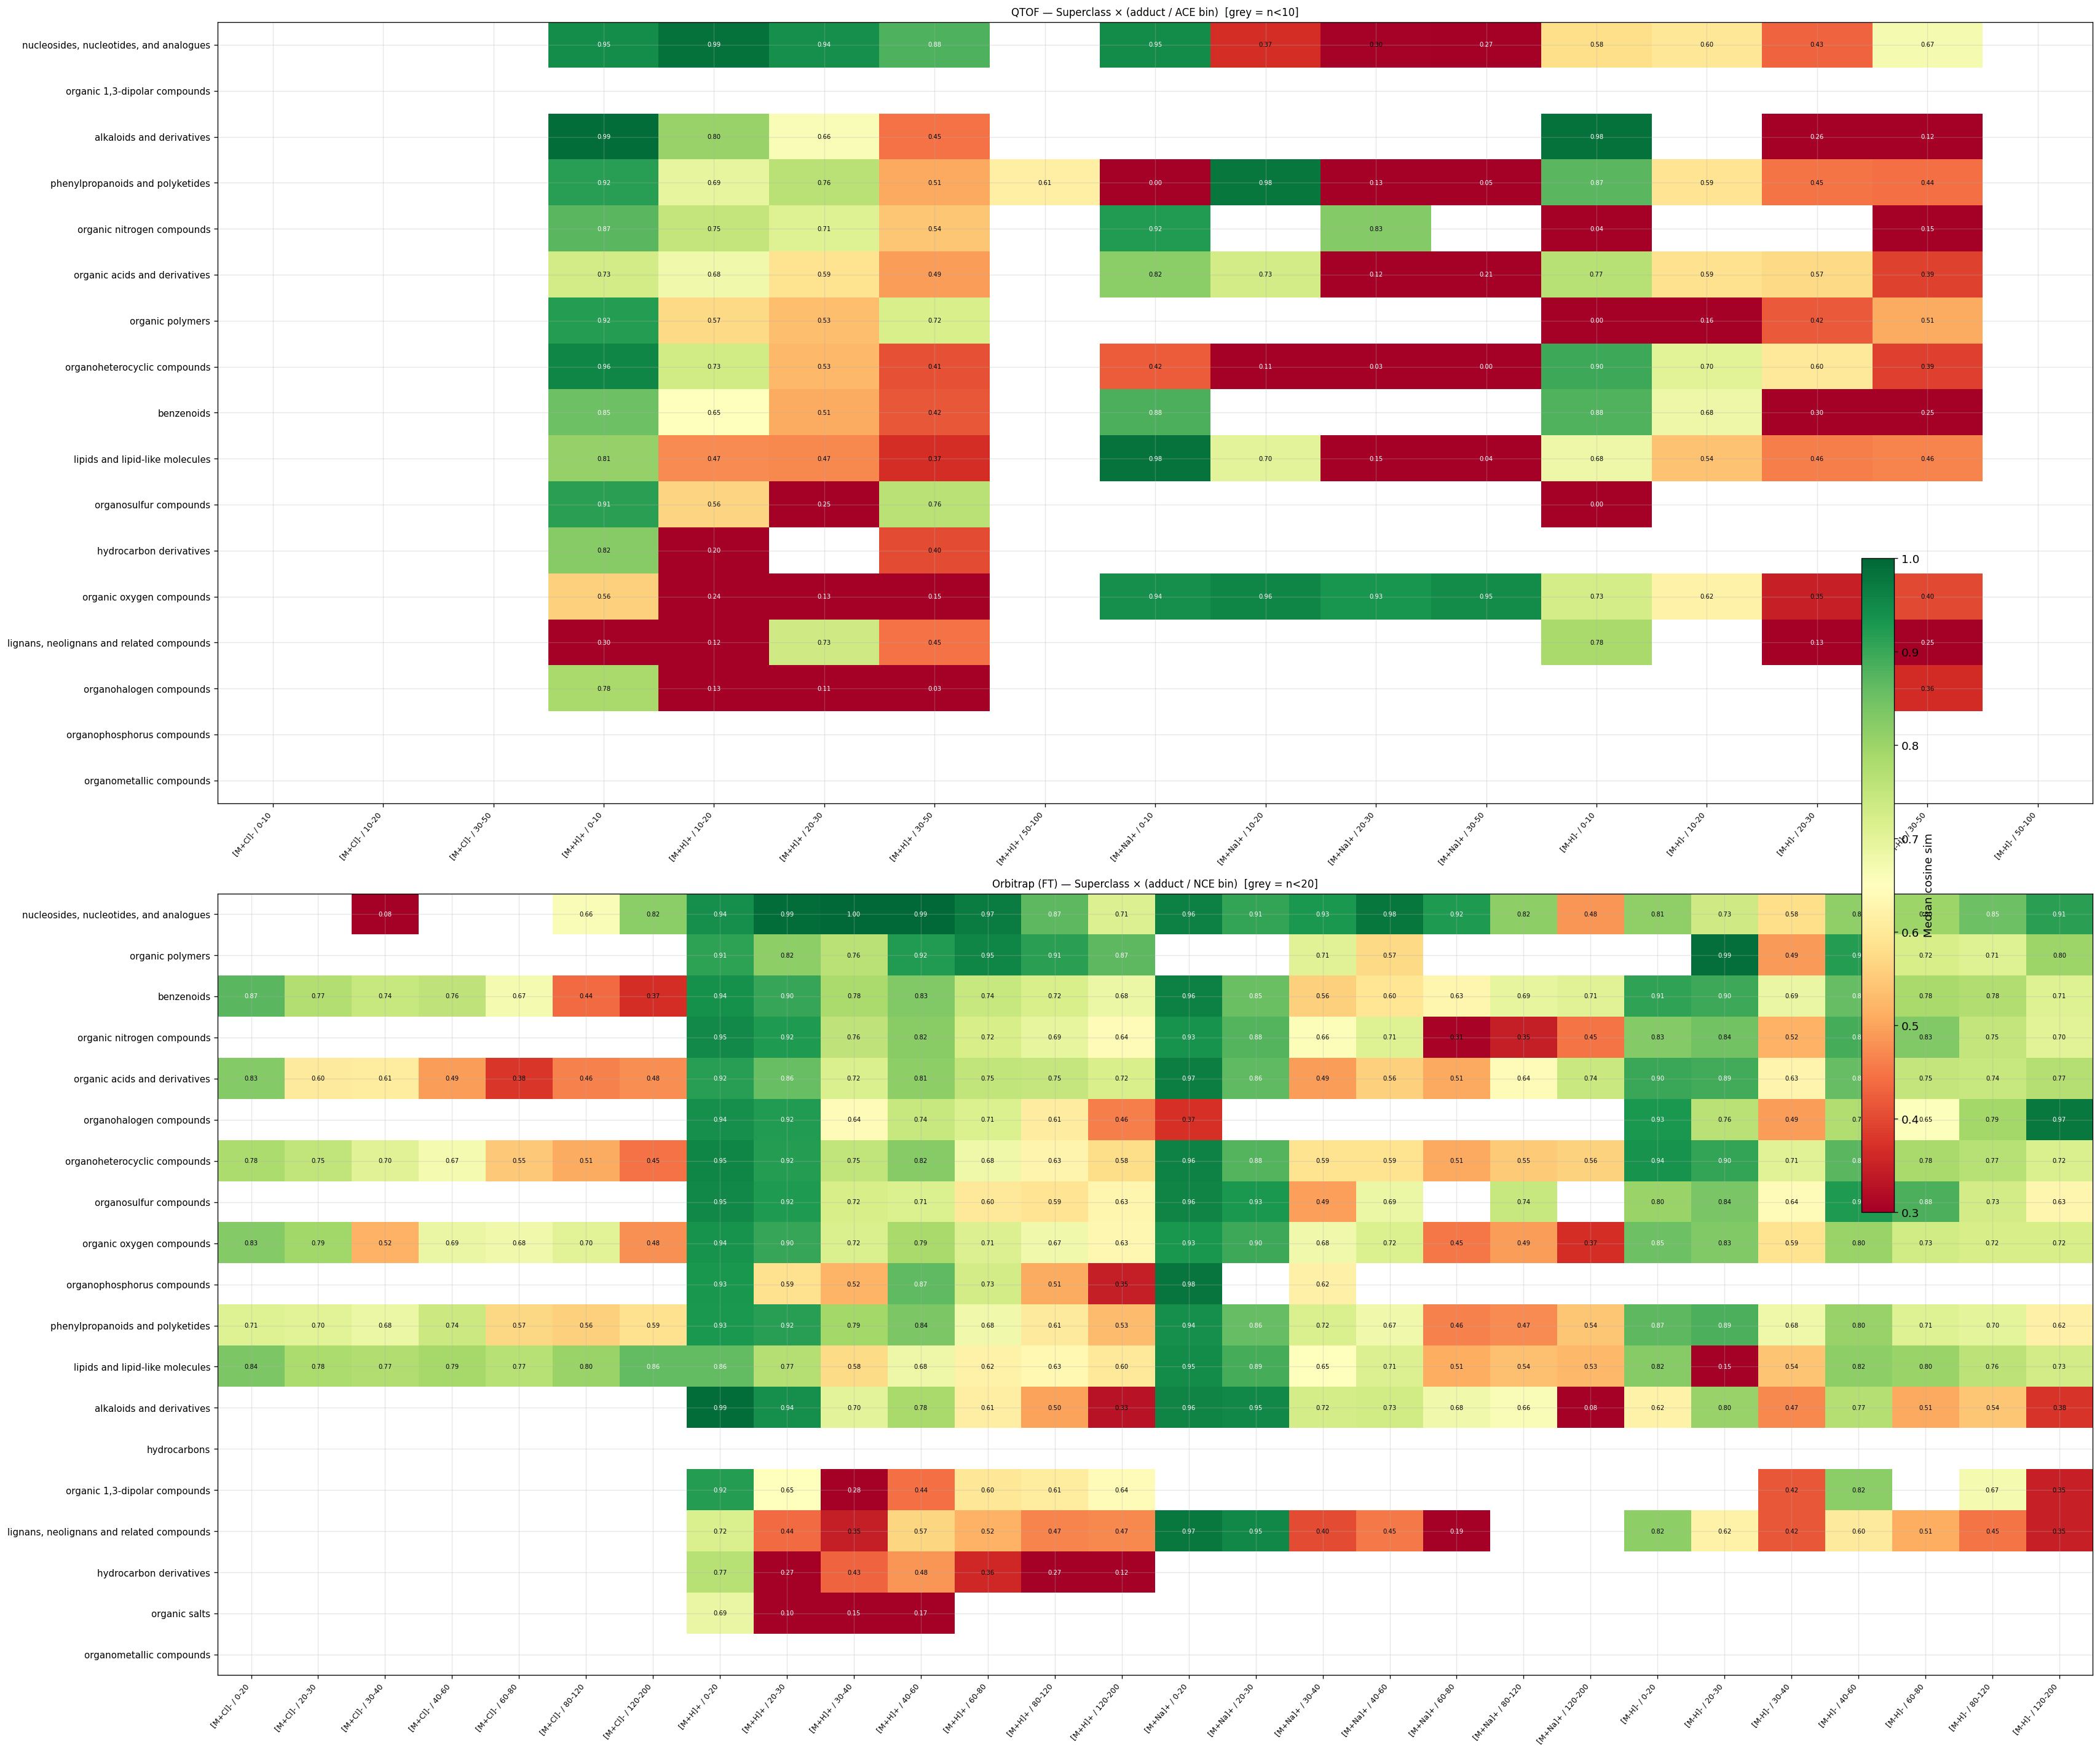

QTOF  heatmap: (17, 17)  non-null cells: 125
FT    heatmap: (19, 28)  non-null cells: 333


In [ ]:
main_adducts = ["[M+H]+", "[M-H]-", "[M+Na]+", "[M+Cl]-"]


def make_cf_heatmap(df_in, inst_label, cf_col, min_n=20):
    """Return pivot table (rows=cf_col, cols=adduct/CE bin) of median cosine sim.

    Uses ACE (eV) for QTOF and NCE (%) for FT/IT, with instrument-specific bin edges
    defined in CE_CONFIG.
    """
    cfg = CE_CONFIG[inst_label]
    ce_col = cfg["col"]
    ce_edges = cfg["edges"]
    ce_labels = cfg["labels"]
    ce_label = cfg["label"]

    d = df_in[
        df_in["prec_type"].isin(main_adducts)
        & df_in[ce_col].notna()
        & (df_in[ce_col] > 0)
        & (df_in[ce_col] <= ce_edges[-1])
        & df_in["inst_type"].eq(inst_label)
        & df_in[cf_col].notna()
    ].copy()
    d["ce_bin"] = pd.cut(d[ce_col], bins=ce_edges, labels=ce_labels, right=True)
    d["adduct_ce"] = d["prec_type"] + " / " + d["ce_bin"].astype(str)
    piv = (
        d.groupby([cf_col, "adduct_ce"])["cos_sim_0.01"]
        .agg(["median", "count"])
        .reset_index()
    )
    piv.loc[piv["count"] < min_n, "median"] = float("nan")
    heat = piv.pivot(index=cf_col, columns="adduct_ce", values="median")
    # row order: by overall median within this slice
    row_ord = d.groupby(cf_col)["cos_sim_0.01"].median().sort_values(ascending=False).index
    heat = heat.reindex(row_ord)
    # column order: by adduct then CE bin rank
    col_ord = sorted(
        heat.columns,
        key=lambda x: (
            x.split(" / ")[0],
            ce_labels.index(x.split(" / ")[1]) if x.split(" / ")[1] in ce_labels else 99,
        ),
    )
    return heat[col_ord]


def plot_heatmap(heat, title, ax):
    im = ax.imshow(heat.values, aspect="auto", cmap="RdYlGn", vmin=0.3, vmax=1.0)
    ax.set_xticks(range(len(heat.columns)))
    ax.set_xticklabels(heat.columns, rotation=50, ha="right", fontsize=7.5)
    ax.set_yticks(range(len(heat.index)))
    ax.set_yticklabels(heat.index, fontsize=9)
    ax.set_title(title, fontsize=10)
    for i in range(len(heat.index)):
        for j in range(len(heat.columns)):
            v = heat.values[i, j]
            if not np.isnan(v):
                ax.text(
                    j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                    color="black" if 0.3 < v < 0.85 else "white",
                )
    return im


heat_qt = make_cf_heatmap(df, "QTOF", "superklass", min_n=10)
heat_ft = make_cf_heatmap(df, "FT",   "superklass", min_n=20)

n_cols = max(len(heat_qt.columns), len(heat_ft.columns))
n_rows = max(len(heat_qt.index),   len(heat_ft.index))

fig, axes = plt.subplots(2, 1, figsize=(n_cols * 0.95 + 2, n_rows * 1.1 + 3))
im0 = plot_heatmap(heat_qt, "QTOF — Superclass × (adduct / ACE bin)  [grey = n<10]",  axes[0])
im1 = plot_heatmap(heat_ft, "Orbitrap (FT) — Superclass × (adduct / NCE bin)  [grey = n<20]", axes[1])
fig.colorbar(im1, ax=axes, label="Median cosine sim", fraction=0.02, pad=0.04)
plt.tight_layout()
plt.show()

print(f"QTOF  heatmap: {heat_qt.shape}  non-null cells: {heat_qt.notna().sum().sum()}")
print(f"FT    heatmap: {heat_ft.shape}  non-null cells: {heat_ft.notna().sum().sum()}")

/tmp/ipykernel_925805/2457587856.py:14: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


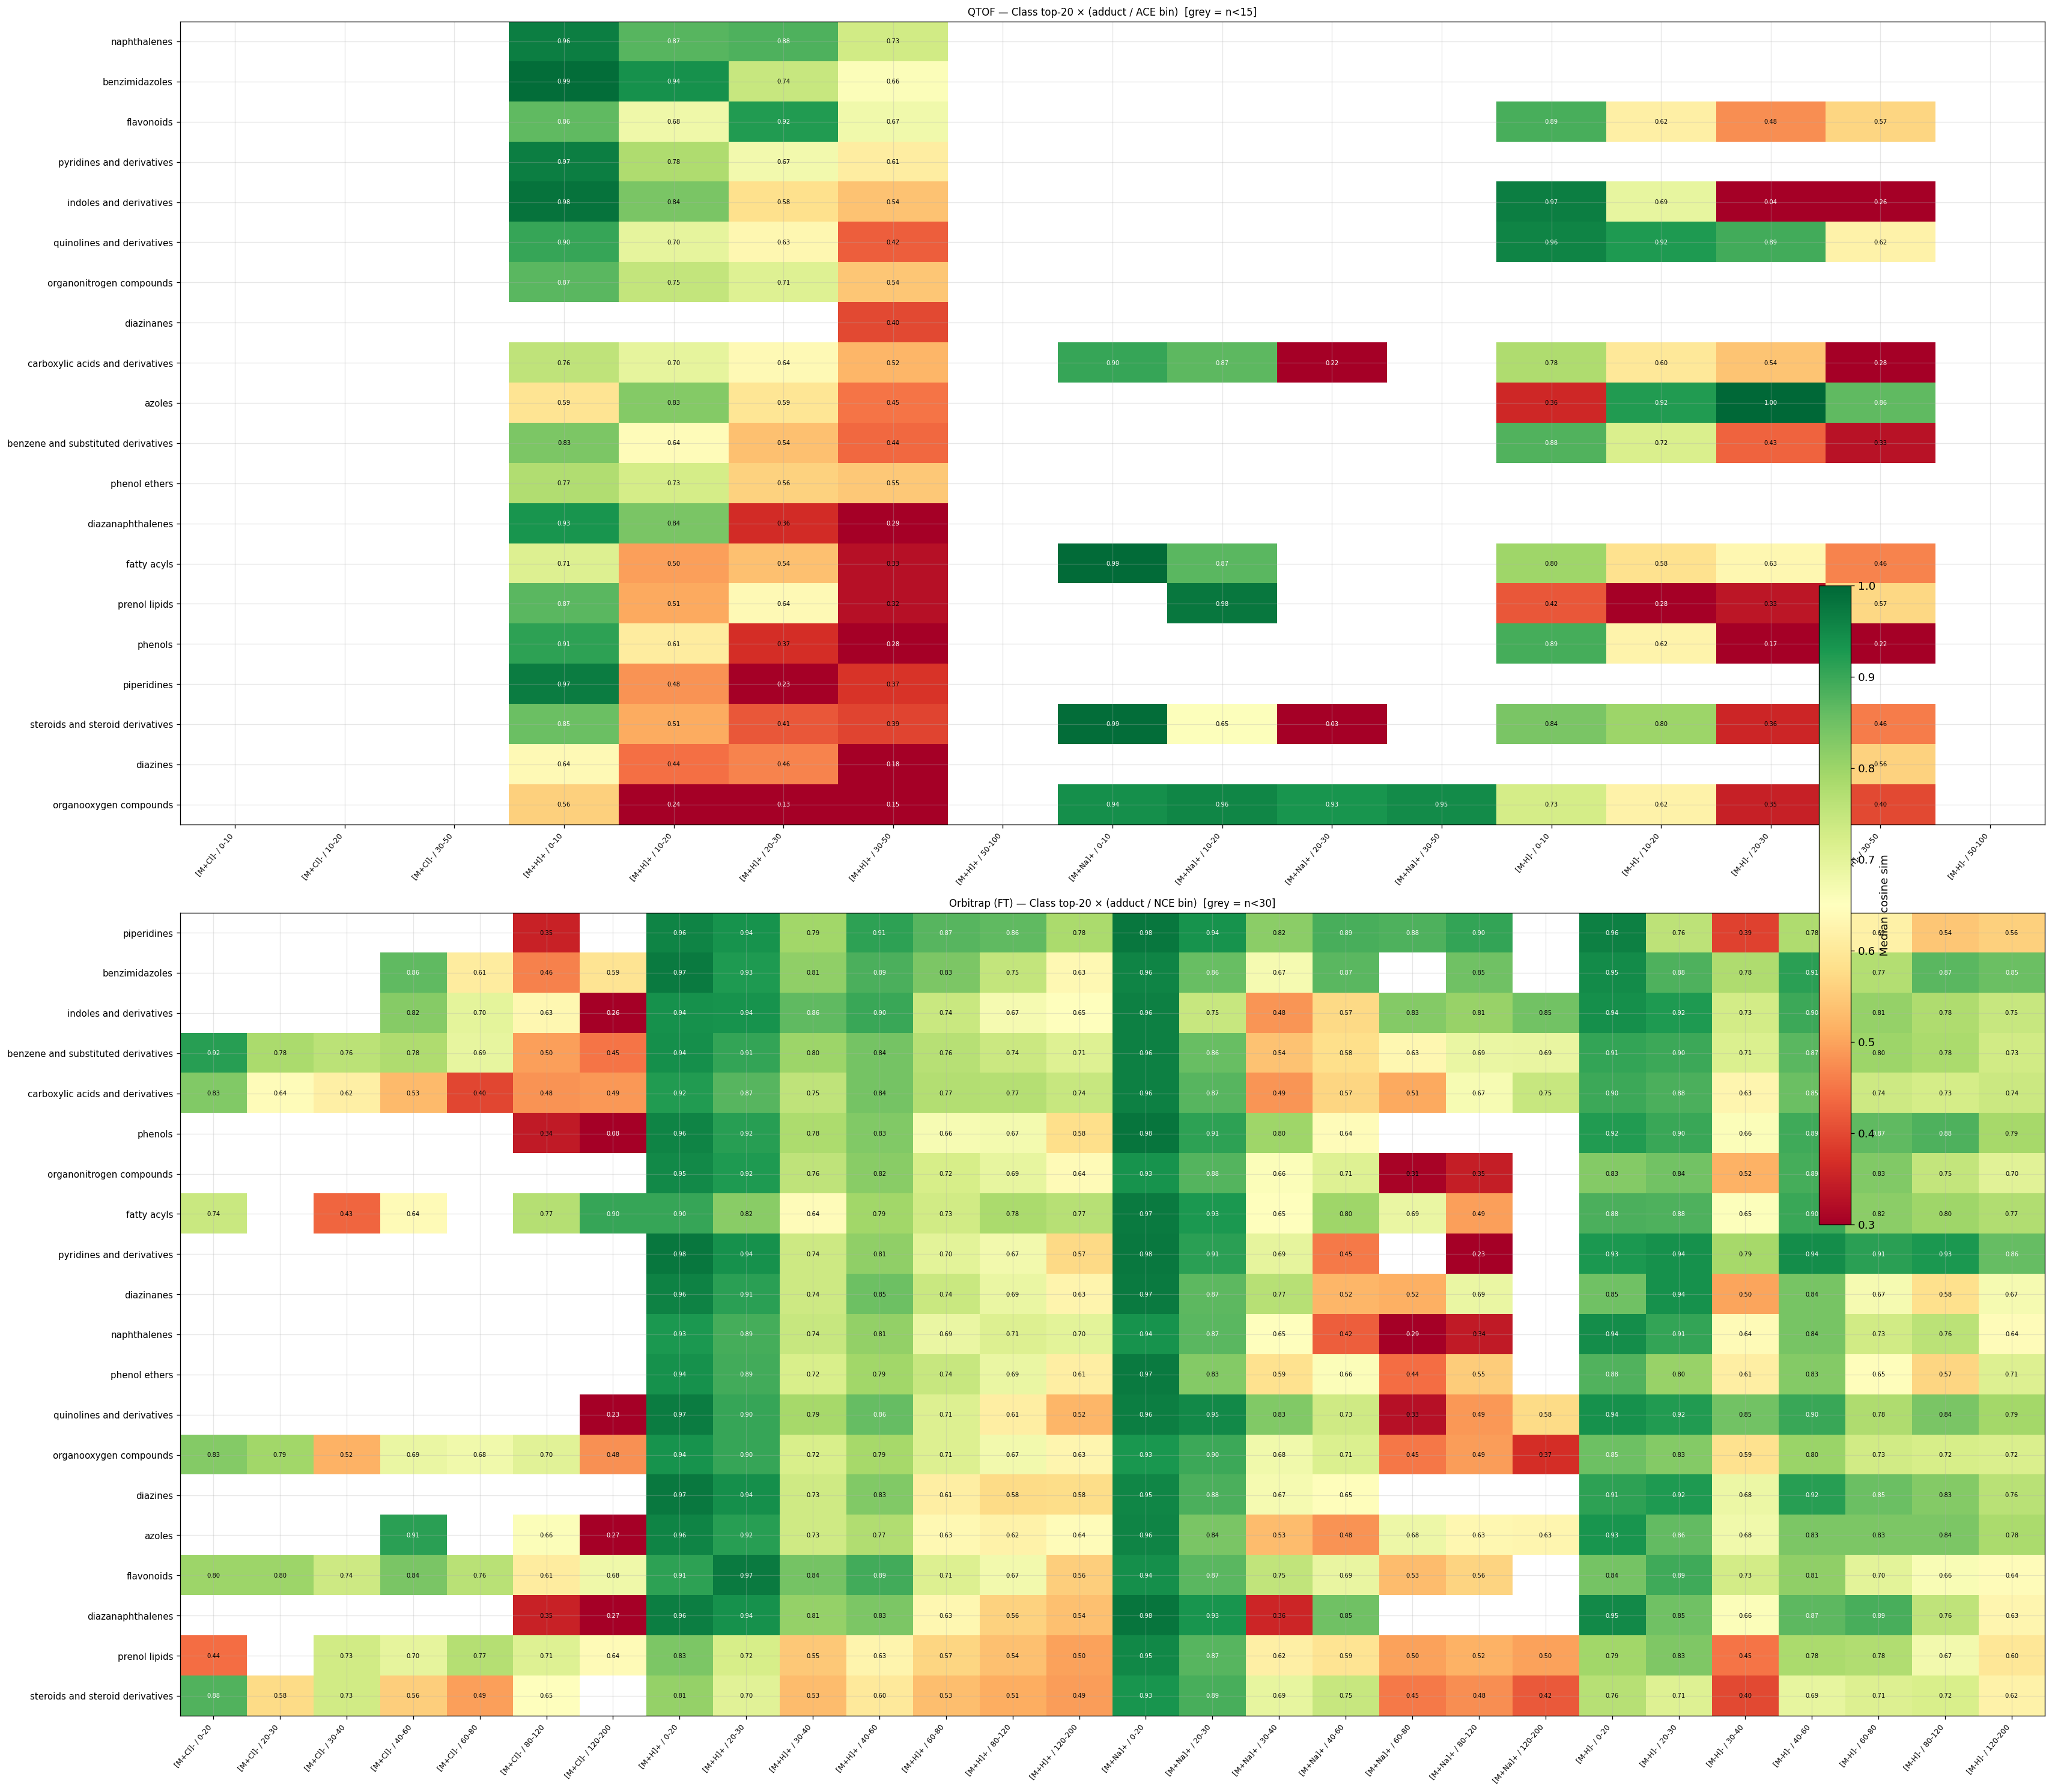

QTOF  heatmap: (20, 17)  non-null: 135
FT    heatmap: (20, 28)  non-null: 462


In [ ]:
top20_klass = df["klass"].value_counts().head(20).index.tolist()
df_kl = df[df["klass"].isin(top20_klass)]

heat_kl_qt = make_cf_heatmap(df_kl, "QTOF", "klass", min_n=15)
heat_kl_ft = make_cf_heatmap(df_kl, "FT",   "klass", min_n=30)

n_cols = max(len(heat_kl_qt.columns), len(heat_kl_ft.columns))
n_rows = max(len(heat_kl_qt.index),   len(heat_kl_ft.index))

fig, axes = plt.subplots(2, 1, figsize=(n_cols * 0.95 + 2, n_rows * 1.1 + 3))
im0 = plot_heatmap(heat_kl_qt, "QTOF — Class top-20 × (adduct / ACE bin)  [grey = n<15]",  axes[0])
im1 = plot_heatmap(heat_kl_ft, "Orbitrap (FT) — Class top-20 × (adduct / NCE bin)  [grey = n<30]", axes[1])
fig.colorbar(im1, ax=axes, label="Median cosine sim", fraction=0.02, pad=0.04)
plt.tight_layout()
plt.show()

print(f"QTOF  heatmap: {heat_kl_qt.shape}  non-null: {heat_kl_qt.notna().sum().sum()}")
print(f"FT    heatmap: {heat_kl_ft.shape}  non-null: {heat_kl_ft.notna().sum().sum()}")

## 17. Summary Table

In [ ]:
thresholds = [0.2, 0.5, 0.7, 0.9]

summary = {}
for t in thresholds:
    summary[f"cos_sim >= {t}"] = (df["cos_sim_0.01"] >= t).mean()

summary["mean cos_sim"] = df["cos_sim_0.01"].mean()
summary["median cos_sim"] = df["cos_sim_0.01"].median()
summary["mean cos_hun"] = df["cos_hun"].mean()
summary["median cos_hun"] = df["cos_hun"].median()
summary["n_spectra"] = len(df)
summary["n_molecules"] = df["mol_id"].nunique()

pd.Series(summary).round(4).to_frame("value")

,value
cos_sim >= 0.2,0.8653
cos_sim >= 0.5,0.6913
cos_sim >= 0.7,0.5498
cos_sim >= 0.9,0.3451
mean cos_sim,0.6584
median cos_sim,0.7589
mean cos_hun,0.6811
median cos_hun,0.7855
n_spectra,764637.0000
n_molecules,28256.0000


In [ ]:
del df
gc.collect()
